# A1

In [18]:
weight_decay = 0.01
max_epoch = 100
batch_size = 128
patience = 5
initial_lr = 0.001

In [19]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [20]:
import common_utils
import pandas as pd

common_utils.set_seed()
df = pd.read_csv(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_gtzan.csv")
display(df.head())

,filename,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,blues.00000.0.wav,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,3714.560359,...,-2.853603,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767
1,blues.00000.1.wav,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,3869.682242,...,4.074709,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081
2,blues.00000.2.wav,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,3997.639160,...,4.806280,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122
3,blues.00000.3.wav,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,3568.300218,...,-1.359111,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678
4,blues.00000.4.wav,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,3469.992864,...,2.092937,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694


In [21]:
test_size = int(len(df)/4)
train_size = len(df) - test_size

# Add class column
df['label'] = 0  # default to 0
df.loc[df['filename'].str.startswith('metal'), 'label'] = 1

df_train_unscaled, y_train, df_test_unscaled, y_test = common_utils.split_dataset(df, ["filename", "label"], test_size, 0)

nd_train, nd_test = common_utils.preprocess_dataset(df_train_unscaled, df_test_unscaled)

from torch.utils.data import DataLoader
# may not use the conversion in AudioDataset, must convert to tensor manually due to audiodataset handling tensors and dataframes but not numpy arrays given by other methods in common utils
train_load = DataLoader(common_utils.AudioDataset(nd_train,
    torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)
test_load = DataLoader(common_utils.AudioDataset(nd_test,
    torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)


In [22]:
y_train

array([1, 0, 1, ..., 1, 0, 0], dtype=int64)

In [23]:
import torch
import torch.nn as nn

model = common_utils.MLP()
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), weight_decay=weight_decay, lr = initial_lr)
early_stopper = common_utils.EarlyStopper(patience = 5)

In [24]:
def train_loop(dataloader, model, loss_fn, optimizer):
    train_loss= 0
    for _batch, (X, Y) in enumerate(dataloader):
        pred = model(X)
        loss = loss_fn(pred, Y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    return train_loss

def test_loop(dataloader, model, loss_fn):
    test_loss = 0
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
    return test_loss

In [25]:
train_losses = []
test_losses = []
epochs = []

for epoch in range(max_epoch):
    train_loss = train_loop(train_load, model, loss_fn, optimizer)
    test_loss = test_loop(test_load, model, loss_fn)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    epochs.append(epoch)

    if early_stopper.early_stop(test_loss):
        break

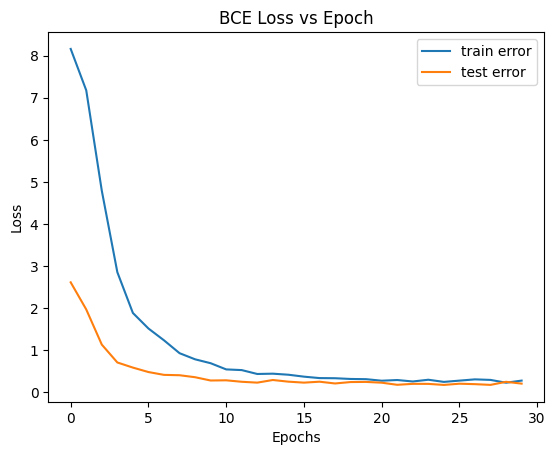

In [26]:
import matplotlib.pyplot as plt 
import numpy as np

plt.plot(epochs, train_losses, label= "train error")
plt.plot(epochs, test_losses, label= "test error")
plt.title("BCE Loss vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [27]:
import shap
features = common_utils.extract_features(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_test.wav")
features.drop(labels = ["filename"], axis=1, inplace=True)
# display(features)
features = torch.tensor(features.to_numpy().astype(np.float32), dtype = torch.float)

background_data = 0
for X_batch, Y_batch in train_load:
    background_data = X_batch  
    break  # Take only the first batch

explainer = shap.DeepExplainer(model, background_data)
shap_values = explainer(features)
shap_array = shap_values.values  

# Remove singleton axes
shap_array = np.squeeze(shap_array)   # → shape: (n_features,)

# Mean absolute shap value per feature
feature_importance = np.abs(shap_array)  # absolute SHAP values

# Get top 5 indices
top5_indices = np.argsort(feature_importance)[-5:][::-1]
print("Top 5 Feature Indices:", top5_indices)

print("Top 5 SHAP Values:", feature_importance[top5_indices])

# Map to feature names
feature_names = df.columns[1:]  # ensure these match the 57 features
top5_names = [feature_names[i] for i in top5_indices]
print("Top 5 influential features:", top5_names)

Top 5 Feature Indices: [9 7 5 8 4]
Top 5 SHAP Values: [0.40476352 0.08182067 0.05528307 0.00801922 0.00435503]
Top 5 influential features: ['rolloff_var', 'spectral_bandwidth_var', 'spectral_centroid_var', 'rolloff_mean', 'spectral_centroid_mean']


# Q2

In [41]:
no_folds = 5
fold_size = int(1000 / no_folds)
# expanded lr grid including 1e-3 and 1e-2 (already present)
lr_list = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]

In [42]:
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()
standard_scaler = preprocessing.StandardScaler()

df_cpy = df.copy()
df_cpy = df.sample(frac=1).reset_index(drop=True)
df_cpy['label'] = label_encoder.fit_transform(df_cpy['label'])
nd_X = df_cpy.drop(["filename", "label"], axis = 1).to_numpy()
nd_Y = df_cpy["label"].to_numpy().reshape(-1, 1)
nd_X = standard_scaler.fit_transform(nd_X)

In [53]:
from sklearn.metrics import roc_auc_score
import time 

def train(X, Y):
    performance = np.zeros((5, len(lr_list), 2, 5), dtype=np.float64)
    X_Y = np.zeros([5, len(lr_list), 2, 2], dtype=object)

    for lr_idx, lr in enumerate(lr_list):
        for fold in range(no_folds):
            idx_start, idx_end = fold*fold_size, (fold+1)*fold_size
            x_test, y_test = X[idx_start:idx_end], Y[idx_start:idx_end]
            x_train  = np.append(X[:idx_start], X[idx_end:], axis=0)
            y_train = np.append(Y[:idx_start], Y[idx_end:], axis=0) 

            t_start = time.time()
            
            model = common_utils.MLP()
            # switch to Adam optimizer for more stable small-batch updates
            optimizer = torch.optim.Adam(model.parameters(), lr=lr)
            loss_fn = nn.BCELoss()
            early_stopper = common_utils.EarlyStopper(patience=patience, min_delta=0)
            
            epoch = 0
            train_loss = 0.0
            test_loss = 0.0
            pred_train = None
            pred_test = None

            x_train_tensor = torch.tensor(x_train, dtype=torch.float)
            y_train_tensor = torch.tensor(y_train, dtype=torch.float)
            x_test_tensor = torch.tensor(x_test, dtype=torch.float)
            y_test_tensor = torch.tensor(y_test, dtype=torch.float)

            for epoch in range(max_epoch):
                model.train()
                optimizer.zero_grad()
                pred_train = model(x_train_tensor)
                train_loss_tensor = loss_fn(pred_train, y_train_tensor)
                train_loss = train_loss_tensor.item()
                train_loss_tensor.backward()
                optimizer.step()

                model.eval()
                with torch.no_grad():
                    pred_test_tensor = model(x_test_tensor)
                    test_loss_tensor = loss_fn(pred_test_tensor, y_test_tensor)
                    test_loss = test_loss_tensor.item()
                    pred_test = pred_test_tensor

                if early_stopper.early_stop(float(test_loss_tensor.item())):
                    break

            t_end = time.time()

            pred_train_prob = pred_train.detach().numpy().ravel()
            pred_test_prob = pred_test.detach().numpy().ravel()
            pred_train_np = (pred_train_prob >= 0.5).astype(int)
            pred_test_np = (pred_test_prob >= 0.5).astype(int)

            performance[fold, lr_idx, 0, 0] = train_loss
            try:
                performance[fold, lr_idx, 0, 1] = roc_auc_score(y_train.ravel(), pred_train_prob)
            except Exception:
                performance[fold, lr_idx, 0, 1] = np.nan
            performance[fold, lr_idx, 0, 2] = t_end - t_start
            performance[fold, lr_idx, 0, 3] = epoch
            performance[fold, lr_idx, 0, 4] = np.mean(pred_train_np == y_train.ravel())

            performance[fold, lr_idx, 1, 0] = test_loss
            try:
                performance[fold, lr_idx, 1, 1] = roc_auc_score(y_test.ravel(), pred_test_prob)
            except Exception:
                performance[fold, lr_idx, 1, 1] = np.nan
            performance[fold, lr_idx, 1, 2] = t_end - t_start
            performance[fold, lr_idx, 1, 3] = epoch
            performance[fold, lr_idx, 1, 4] = np.mean(pred_test_np == y_test.ravel())

            X_Y[fold, lr_idx, 0, 0] = x_train
            X_Y[fold, lr_idx, 0, 1] = y_train
            X_Y[fold, lr_idx, 1, 0] = x_test
            X_Y[fold, lr_idx, 1, 1] = y_test

    return performance, X_Y

In [54]:
performance, X_Y = train(nd_X, nd_Y)

# initialize dicts
X_train_scaled_dict, X_val_scaled_dict, y_train_dict, y_val_dict = {}, {}, {}, {}
for lr_idx, lr in enumerate(lr_list):
    X_train_scaled_dict[lr] = np.array([X_Y[fold, lr_idx, 0, 0] for fold in range(5)])
    X_val_scaled_dict[lr] = np.array([X_Y[fold, lr_idx, 1, 0] for fold in range(5)])
    y_train_dict[lr] = np.array([X_Y[fold, lr_idx, 0, 1] for fold in range(5)])
    y_val_dict[lr] = np.array([X_Y[fold, lr_idx, 1, 1] for fold in range(5)])

In [55]:
performance

array([[[[ 0.69526422,  0.49832654,  0.60451007, 99.        ,
           0.49944444],
         [ 0.69443917,  0.52545255,  0.60451007, 99.        ,
           0.505     ]],

        [[ 0.69325829,  0.49744012,  0.58842301, 99.        ,
           0.48111111],
         [ 0.69345367,  0.50125013,  0.58842301, 99.        ,
           0.445     ]],

        [[ 0.69500369,  0.5189778 ,  0.56489301, 99.        ,
           0.50055556],
         [ 0.69506049,  0.6209621 ,  0.56489301, 99.        ,
           0.495     ]],

        [[ 0.69425112,  0.57075935,  0.56343198, 99.        ,
           0.50055556],
         [ 0.69444853,  0.76387639,  0.56343198, 99.        ,
           0.495     ]],

        [[ 0.68785965,  0.68289961,  0.56890225, 99.        ,
           0.58166667],
         [ 0.68748301,  0.85188519,  0.56890225, 99.        ,
           0.57      ]]],


       [[[ 0.6943177 ,  0.52000319,  0.60271931, 99.        ,
           0.50055556],
         [ 0.69266218,  0.63355342,  0.602

performance shape: (5, 5, 2, 5)
lr	mean_acc	mean_auc
0.0001	0.5180	0.5006
0.0005	0.4780	0.5028
0.0001	0.4890	0.4951
0.0005	0.5270	0.5163
0.01	0.5460	0.8336


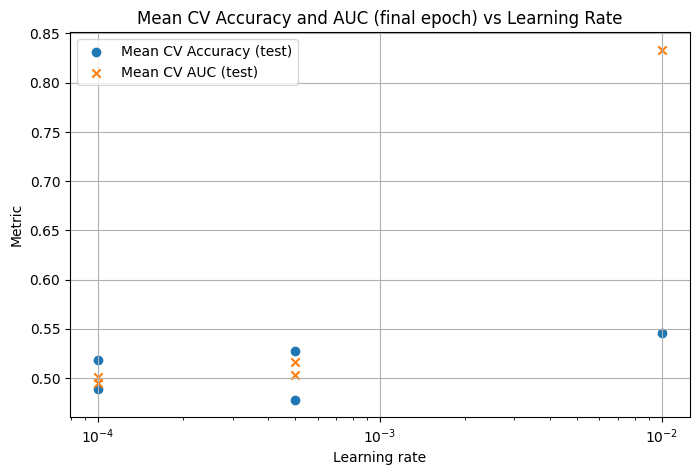

In [56]:
# Aggregate mean CV accuracy and mean CV AUC (final epoch) across folds, then plot vs learning rate
import matplotlib.pyplot as plt
import numpy as np
# 4 due to track loss, auc, time, final epoch (for graphing)
# metric indices used in train(): LOSS=0, AUC=1, TIME=2, EPOCH=3, ACC=4
LOSS_IDX, AUC_IDX, TIME_IDX, EPOCH_IDX, ACC_IDX = 0, 1, 2, 3, 4

# performance expected shape: (no_folds, len(lr_list), 2, 5)
print('performance shape:', performance.shape)

# take metrics from the test split (index 1)
mean_accs = np.nanmean(performance[:, :, 1, ACC_IDX], axis=0)
mean_aucs = np.nanmean(performance[:, :, 1, AUC_IDX], axis=0)

# Print a small summary table
print('lr\tmean_acc\tmean_auc')
for lr, a, auc in zip(lr_list, mean_accs, mean_aucs):
    print(f"{lr}\t{a:.4f}\t{auc:.4f}")

# Scatter plot
plt.figure(figsize=(8,5))
plt.scatter(lr_list, mean_accs, label='Mean CV Accuracy (test)', marker='o')
plt.scatter(lr_list, mean_aucs, label='Mean CV AUC (test)', marker='x')
plt.xscale('log')
plt.xlabel('Learning rate')
plt.ylabel('Metric')
plt.title('Mean CV Accuracy and AUC (final epoch) vs Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

In [60]:
# Diagnostic single-fold training to inspect learning behavior
import numpy as np
import torch
import torch.nn as nn

# use fold 0 and lr=first in lr_list
fold = 0
lr = lr_list[0]

# extract one fold's data
x_train = X_Y[fold, 0, 0, 0]
y_train = X_Y[fold, 0, 0, 1].ravel()
x_test = X_Y[fold, 0, 1, 0]
y_test = X_Y[fold, 0, 1, 1].ravel()

print('Class balance (train):', np.bincount(y_train.astype(int)))
print('Class balance (test):', np.bincount(y_test.astype(int)))

model = common_utils.MLP()
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

x_train_t = torch.tensor(x_train, dtype=torch.float)
y_train_t = torch.tensor(y_train.reshape(-1,1), dtype=torch.float)

x_test_t = torch.tensor(x_test, dtype=torch.float)
y_test_t = torch.tensor(y_test.reshape(-1,1), dtype=torch.float)

epochs = 10
for e in range(epochs):
    model.train()
    optimizer.zero_grad()
    pred = model(x_train_t)
    loss = loss_fn(pred, y_train_t)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        pred_test = model(x_test_t)
        val_loss = loss_fn(pred_test, y_test_t)

    pred_np = pred.detach().numpy().ravel()
    pred_labels = (pred_np >= 0.5).astype(int)
    train_acc = np.mean(pred_labels == y_train.astype(int))

    pred_test_np = pred_test.detach().numpy().ravel()
    pred_test_labels = (pred_test_np >= 0.5).astype(int)
    test_acc = np.mean(pred_test_labels == y_test.astype(int))

    # weight norm for first linear layer
    first_linear = None
    for m in model.mlp_stack:
        if isinstance(m, torch.nn.Linear):
            first_linear = m
            break
    wnorm = first_linear.weight.data.norm().item() if first_linear is not None else None

    print(f"Epoch {e+1}: train_loss={loss.item():.4f}, val_loss={val_loss.item():.4f}, train_acc={train_acc:.4f}, test_acc={test_acc:.4f}, wnorm={wnorm:.4f}")

# show few predictions vs truth
print('Some test preds (probabilities):', pred_test_np[:10])
print('Some test true labels:', y_test[:10].astype(int))

Class balance (train): [899 901]
Class balance (test): [101  99]
Epoch 1: train_loss=0.6925, val_loss=0.6926, train_acc=0.4961, test_acc=0.5050, wnorm=9.2583
Epoch 2: train_loss=0.6925, val_loss=0.6926, train_acc=0.4978, test_acc=0.5050, wnorm=9.2583
Epoch 3: train_loss=0.6921, val_loss=0.6926, train_acc=0.4989, test_acc=0.5050, wnorm=9.2583
Epoch 4: train_loss=0.6925, val_loss=0.6926, train_acc=0.4950, test_acc=0.5050, wnorm=9.2583
Epoch 5: train_loss=0.6924, val_loss=0.6926, train_acc=0.4972, test_acc=0.5050, wnorm=9.2583
Epoch 6: train_loss=0.6922, val_loss=0.6926, train_acc=0.4978, test_acc=0.5050, wnorm=9.2583
Epoch 7: train_loss=0.6917, val_loss=0.6926, train_acc=0.4983, test_acc=0.5050, wnorm=9.2583
Epoch 8: train_loss=0.6923, val_loss=0.6926, train_acc=0.4972, test_acc=0.5050, wnorm=9.2583
Epoch 9: train_loss=0.6919, val_loss=0.6926, train_acc=0.5017, test_acc=0.5050, wnorm=9.2583
Epoch 10: train_loss=0.6922, val_loss=0.6926, train_acc=0.4989, test_acc=0.5050, wnorm=9.2583
Some

In [59]:
# Diagnostic: inspect gradients and parameter updates for first linear layer over two optimization steps
import copy

# prepare tiny subset
x_small = x_train[:64]
y_small = y_train[:64]

model2 = common_utils.MLP()
optimizer2 = torch.optim.SGD(model2.parameters(), lr=lr)
loss_fn2 = nn.BCELoss()

x_small_t = torch.tensor(x_small, dtype=torch.float)
y_small_t = torch.tensor(y_small.reshape(-1,1), dtype=torch.float)

# capture initial weights
first_linear = None
for m in model2.mlp_stack:
    if isinstance(m, torch.nn.Linear):
        first_linear = m
        break

w_before = first_linear.weight.data.clone()

# single step
model2.train()
optimizer2.zero_grad()
pred_small = model2(x_small_t)
loss_small = loss_fn2(pred_small, y_small_t)
loss_small.backward()
# inspect gradient norm
grad_norm = first_linear.weight.grad.data.norm().item()
optimizer2.step()
w_after_step1 = first_linear.weight.data.clone()

# second step
optimizer2.zero_grad()
pred_small = model2(x_small_t)
loss_small2 = loss_fn2(pred_small, y_small_t)
loss_small2.backward()
grad_norm2 = first_linear.weight.grad.data.norm().item()
optimizer2.step()
w_after_step2 = first_linear.weight.data.clone()

print('loss1, grad_norm1:', loss_small.item(), grad_norm)
print('loss2, grad_norm2:', loss_small2.item(), grad_norm2)
print('weight change step1 norm:', (w_after_step1 - w_before).norm().item())
print('weight change step2 norm:', (w_after_step2 - w_after_step1).norm().item())

loss1, grad_norm1: 0.6940364837646484 0.029788393527269363
loss2, grad_norm2: 0.6934289336204529 0.03097200207412243
weight change step1 norm: 2.988390178870759e-06
weight change step2 norm: 3.10493442157167e-06


In [57]:
# Demo: computing accuracy from different prediction formats
import numpy as np
from sklearn.metrics import accuracy_score

# 1) If you have positive-class probabilities (shape (n,))
# Example: pos_probs = all_preds[fold_idx, lr_idx, split][:,1]
# Convert to labels by thresholding at 0.5
pos_probs_example = np.array([0.1, 0.6, 0.8, 0.3])
labels_from_probs = (pos_probs_example >= 0.5).astype(int)
print('labels from pos probs:', labels_from_probs)
print('accuracy (manual):', np.mean((pos_probs_example >= 0.5).astype(int) == np.array([0,1,1,0])))
print('accuracy (sklearn):', accuracy_score(np.array([0,1,1,0]), labels_from_probs))

# 2) If you have two-class probability arrays (shape (n,2)) where columns are [P(neg), P(pos)]
two_class_probs = np.vstack([1 - pos_probs_example, pos_probs_example]).T
labels_from_two_class = np.argmax(two_class_probs, axis=1)
print('\nlabels from two-class probs:', labels_from_two_class)
print('accuracy (two-class):', accuracy_score(np.array([0,1,1,0]), labels_from_two_class))

# 3) If you have logits (unbounded) from the model, apply sigmoid then threshold
logits_example = np.array([-2.0, 1.5, 2.0, -0.8])
pos_probs_from_logits = 1 / (1 + np.exp(-logits_example))
labels_from_logits = (pos_probs_from_logits >= 0.5).astype(int)
print('\nlabels from logits:', labels_from_logits)
print('accuracy (logits):', accuracy_score(np.array([0,1,1,0]), labels_from_logits))

# 4) If you are using arrays stored in all_preds (from train):
#    all_preds[fold, lr_idx, split] is shape (n_samples, 2) with columns [P(neg), P(pos)]
try:
    sample_probs = X_Y[0, 0, 1]  # fold=0, lr_idx=0, test split
    sample_labels = X_Y[0, 0, 1, 1].ravel()  # corresponding true labels
    sample_pred_labels = np.argmax(sample_probs, axis=1)
    print('\nsample pred labels (from all_preds):', sample_pred_labels[:10])
    print('sample true labels:', sample_labels[:10])
    print('sample accuracy:', accuracy_score(sample_labels, sample_pred_labels))
except Exception as e:
    print('\nCould not compute sample accuracy from all_preds/X_Y - maybe train not run or structure differs:', e)

# Edge cases: if only one class present in true labels, accuracy is trivial but roc AUC is undefined.

# Helper function to compute accuracy from positive probs and true labels
def accuracy_from_pos_probs(pos_probs, y_true, threshold=0.5):
    y_pred = (np.asarray(pos_probs).ravel() >= threshold).astype(int)
    return float(np.mean(y_pred == np.ravel(y_true)))

# Example usage
# accuracy_from_pos_probs(all_preds[0,0,1][:,1], X_Y[0,0,1,1])


labels from pos probs: [0 1 1 0]
accuracy (manual): 1.0
accuracy (sklearn): 1.0

labels from two-class probs: [0 1 1 0]
accuracy (two-class): 1.0

labels from logits: [0 1 1 0]
accuracy (logits): 1.0

Could not compute sample accuracy from all_preds/X_Y - maybe train not run or structure differs: axis 1 is out of bounds for array of dimension 1
